Install packages

In [1]:
!pip install openpyxl pyarrow -q
print("Done")

Done


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Environment ready.")
print(f"Figures will save to: {FIGURES}")
print(f"Processed data will save to: {PROCESSED}")


Environment ready.
Figures will save to: /content/figures
Processed data will save to: /content/processed


In [4]:
from google.colab import files

print("A file picker will appear below.")
print("Upload: WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Download it first from: https://www.kaggle.com/datasets/blastchar/telco-customer-churn")
print()

uploaded = files.upload()
print("Upload complete.")


A file picker will appear below.
Upload: WA_Fn-UseC_-Telco-Customer-Churn.csv
Download it first from: https://www.kaggle.com/datasets/blastchar/telco-customer-churn



Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Upload complete.


In [5]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")
df.head()


Shape: 7,043 rows x 21 columns

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
print("=" * 60)
print("DATA QUALITY REPORT — Telco Customer Churn")
print("=" * 60)
print(f"\nRows     : {df.shape[0]:,}")
print(f"Columns  : {df.shape[1]}")

nulls = df.isnull().sum()
print("\nNull values per column:")
if nulls.sum() == 0:
    print("  None found.")
else:
    print(nulls[nulls > 0].to_string())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

# TotalCharges is stored as object — find non-numeric values
bad_charges = df[pd.to_numeric(df['TotalCharges'], errors='coerce').isna()]
print(f"\nTotalCharges — non-numeric values found: {len(bad_charges)}")
print(f"  These rows all have tenure = {bad_charges['tenure'].unique()}")
print("  Reason: brand new subscribers with no billing history yet.")

print("\nData types:")
print(df.dtypes.to_string())


DATA QUALITY REPORT — Telco Customer Churn

Rows     : 7,043
Columns  : 21

Null values per column:
  None found.

Duplicate rows: 0

TotalCharges — non-numeric values found: 11
  These rows all have tenure = [0]
  Reason: brand new subscribers with no billing history yet.

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object


In [7]:
# Fix 1: TotalCharges — convert to float, fill new-subscriber blanks with 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
fixed = df['TotalCharges'].isna().sum()
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
print(f"Fixed {fixed} TotalCharges values (tenure=0 subscribers set to £0)")

# Fix 2: Encode churn as binary integer
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

print(f"\nNull values remaining: {df.isnull().sum().sum()}")
print(f"Shape unchanged: {df.shape}")
print("\nChurn label distribution:")
print(
    df['Churn'].value_counts()
    .to_frame('Count')
    .assign(Pct=lambda x: (x['Count'] / len(df) * 100).round(1))
    .to_string()
)


Fixed 11 TotalCharges values (tenure=0 subscribers set to £0)

Null values remaining: 0
Shape unchanged: (7043, 22)

Churn label distribution:
       Count   Pct
Churn             
No      5174  73.5
Yes     1869  26.5


In [8]:
churn_rate    = df['Churn_Binary'].mean()
retained_rate = 1 - churn_rate
mrr_active    = df[df['Churn_Binary'] == 0]['MonthlyCharges'].sum()
mrr_churned   = df[df['Churn_Binary'] == 1]['MonthlyCharges'].sum()

print("=" * 60)
print("CHURN RATE SUMMARY")
print("=" * 60)
print(f"Total subscribers            : {len(df):,}")
print(f"Active (retained)            : {(df['Churn_Binary']==0).sum():,}  ({retained_rate*100:.1f}%)")
print(f"Churned                      : {(df['Churn_Binary']==1).sum():,}  ({churn_rate*100:.1f}%)")
print(f"\nMRR from active subscribers  : £{mrr_active:,.0f}")
print(f"MRR lost to churned base     : £{mrr_churned:,.0f}")
print(f"\nIndustry benchmark (monthly) : 5–8%")
status = 'ABOVE benchmark — retention is a critical priority' if churn_rate > 0.08 else 'Within benchmark'
print(f"StreamVault churn rate       : {churn_rate*100:.1f}%  — {status}")


CHURN RATE SUMMARY
Total subscribers            : 7,043
Active (retained)            : 5,174  (73.5%)
Churned                      : 1,869  (26.5%)

MRR from active subscribers  : £316,986
MRR lost to churned base     : £139,131

Industry benchmark (monthly) : 5–8%
StreamVault churn rate       : 26.5%  — ABOVE benchmark — retention is a critical priority


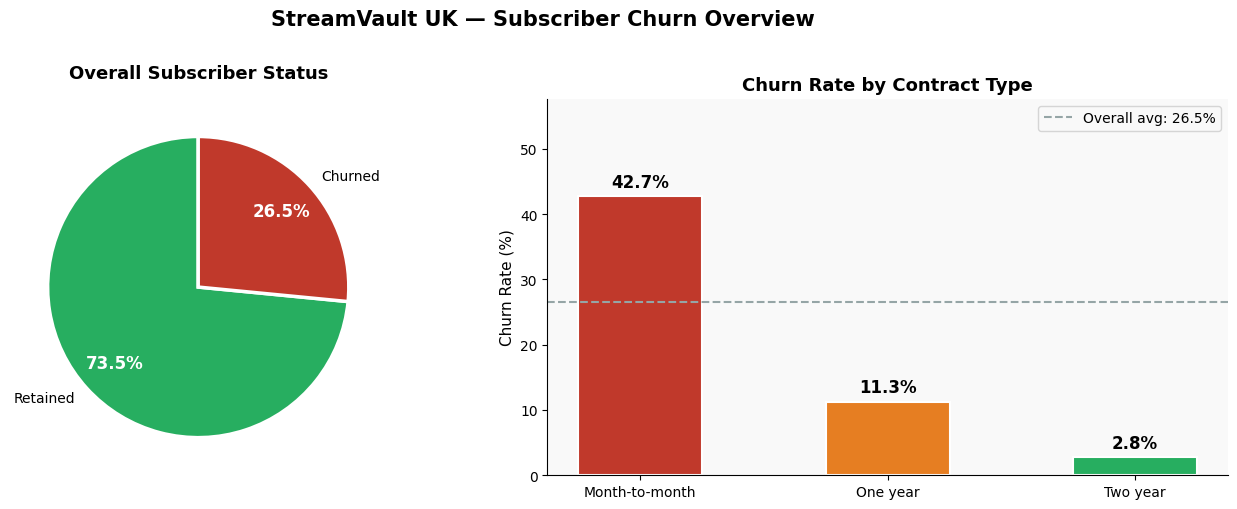


Business interpretation:
Month-to-month subscribers churn at 42.7%.
That is 15x the rate of two-year subscribers (2.8%).
Highest single priority: convert monthly subscribers to annual contracts in months 1–3.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('StreamVault UK — Subscriber Churn Overview', fontsize=15, fontweight='bold', y=1.01)

# Left: pie chart
wedges, _, autotexts = axes[0].pie(
    [retained_rate, churn_rate],
    labels=['Retained', 'Churned'],
    colors=[GREEN, RED],
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5},
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')
    at.set_color('white')
axes[0].set_title('Overall Subscriber Status', fontweight='bold', pad=15)

# Right: churn rate by contract type
contract_churn = df.groupby('Contract')['Churn_Binary'].mean().sort_values(ascending=False)
bar_colors = [RED if v > 0.15 else ORANGE if v > 0.08 else GREEN for v in contract_churn.values]
bars = axes[1].bar(
    contract_churn.index,
    contract_churn.values * 100,
    color=bar_colors, width=0.5, edgecolor='white', linewidth=1.5
)
axes[1].axhline(
    y=churn_rate * 100, color=GREY, linestyle='--', linewidth=1.5,
    label=f'Overall avg: {churn_rate*100:.1f}%'
)
axes[1].set_title('Churn Rate by Contract Type', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, contract_churn.max() * 100 * 1.35)
for bar, val in zip(bars, contract_churn.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
        f'{val*100:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold'
    )
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES / '01_churn_overview.png', dpi=150, bbox_inches='tight')
plt.show()

mm_rate = contract_churn['Month-to-month']
ty_rate = contract_churn['Two year']
print(f"\nBusiness interpretation:")
print(f"Month-to-month subscribers churn at {mm_rate*100:.1f}%.")
print(f"That is {mm_rate/ty_rate:.0f}x the rate of two-year subscribers ({ty_rate*100:.1f}%).")
print("Highest single priority: convert monthly subscribers to annual contracts in months 1–3.")


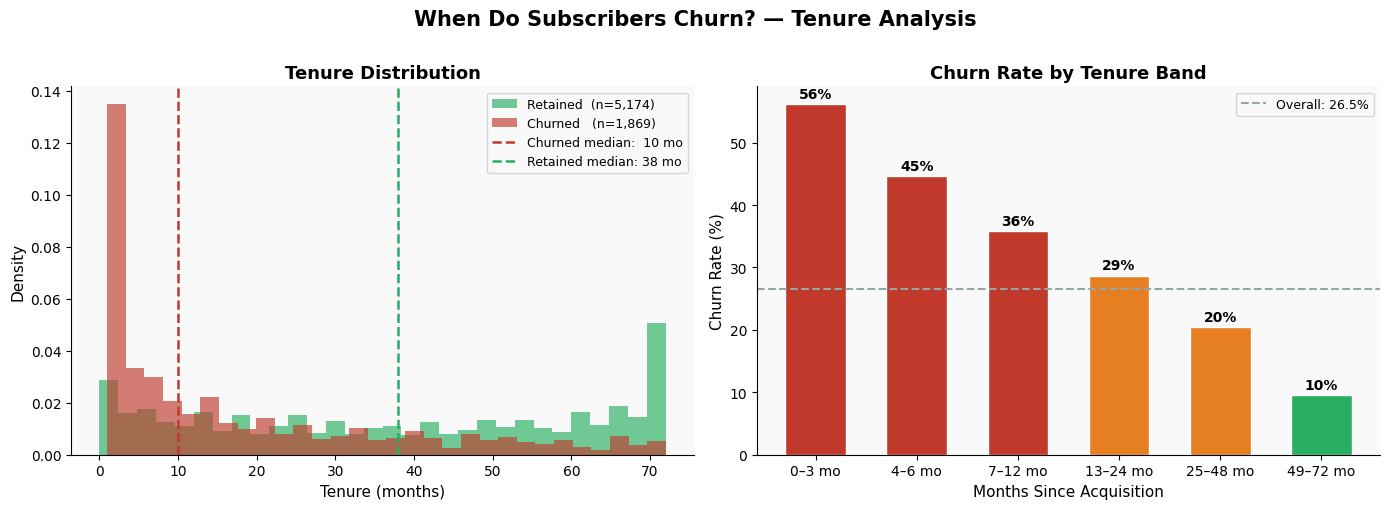


Business interpretation:
Months 0–3 churn rate  : 56%
Months 49–72 churn rate: 10%
The first 90 days is the critical retention window.
Subscribers who survive past 24 months have very low ongoing churn risk.
Investment priority: onboarding quality and early value delivery.


In [10]:
churned  = df[df['Churn_Binary'] == 1]['tenure']
retained = df[df['Churn_Binary'] == 0]['tenure']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('When Do Subscribers Churn? — Tenure Analysis', fontsize=15, fontweight='bold', y=1.01)

# Left: overlapping histograms
axes[0].hist(retained, bins=30, alpha=0.65, color=GREEN, label=f'Retained  (n={len(retained):,})', density=True)
axes[0].hist(churned,  bins=30, alpha=0.65, color=RED,   label=f'Churned   (n={len(churned):,})',  density=True)
axes[0].axvline(churned.median(),  color=RED,   linestyle='--', lw=1.8, label=f'Churned median:  {churned.median():.0f} mo')
axes[0].axvline(retained.median(), color=GREEN, linestyle='--', lw=1.8, label=f'Retained median: {retained.median():.0f} mo')
axes[0].set_title('Tenure Distribution', fontweight='bold')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Density')
axes[0].legend(fontsize=9)

# Right: churn rate by tenure band
bins_t   = [0, 3, 6, 12, 24, 48, 72]
labels_t = ['0–3 mo', '4–6 mo', '7–12 mo', '13–24 mo', '25–48 mo', '49–72 mo']
df['TenureBand'] = pd.cut(df['tenure'], bins=bins_t, labels=labels_t, include_lowest=True)
tb = df.groupby('TenureBand', observed=True)['Churn_Binary'].mean()

bar_colors2 = [RED if v > 0.35 else ORANGE if v > 0.20 else GREEN for v in tb.values]
bars2 = axes[1].bar(tb.index, tb.values * 100, color=bar_colors2, width=0.6, edgecolor='white')
axes[1].axhline(churn_rate * 100, color=GREY, linestyle='--', lw=1.5, label=f'Overall: {churn_rate*100:.1f}%')
axes[1].set_title('Churn Rate by Tenure Band', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('Months Since Acquisition')
for bar, val in zip(bars2, tb.values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{val*100:.0f}%', ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '02_tenure_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

early = df[df['TenureBand'] == '0–3 mo']['Churn_Binary'].mean()
late  = df[df['TenureBand'] == '49–72 mo']['Churn_Binary'].mean()
print(f"\nBusiness interpretation:")
print(f"Months 0–3 churn rate  : {early*100:.0f}%")
print(f"Months 49–72 churn rate: {late*100:.0f}%")
print("The first 90 days is the critical retention window.")
print("Subscribers who survive past 24 months have very low ongoing churn risk.")
print("Investment priority: onboarding quality and early value delivery.")


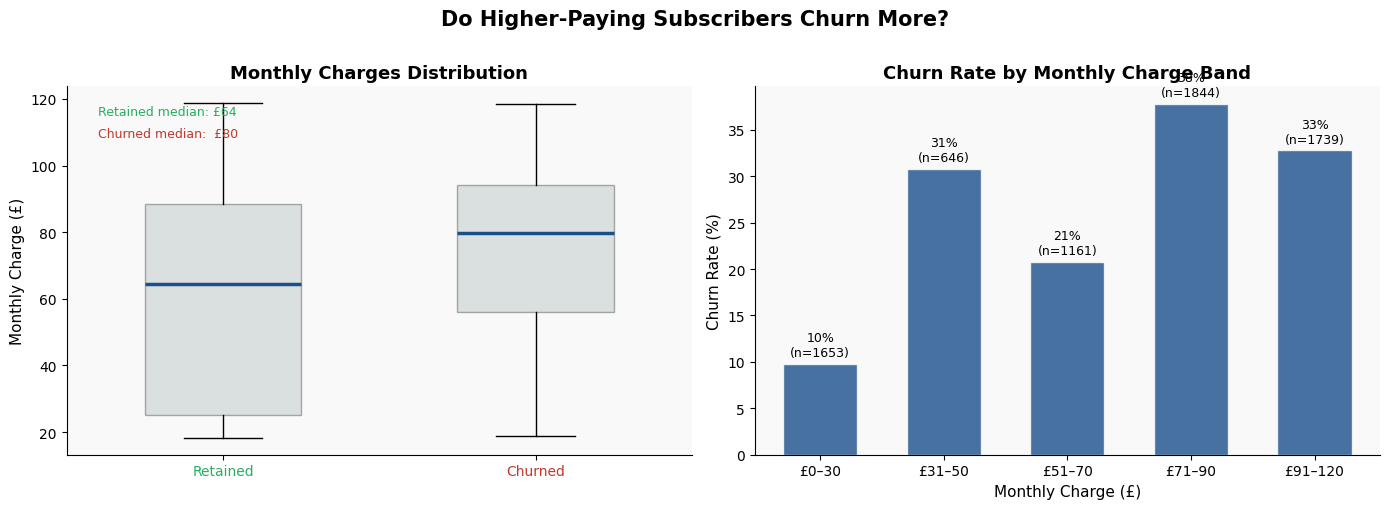


Business interpretation:
Lowest band £0–30 churn rate   : 10%
Highest band £91–120 churn rate: 33%
Confirmed: higher-paying subscribers churn at a higher rate.
Recommended action: value reinforcement campaign for £70+ subscribers in months 1–6.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Do Higher-Paying Subscribers Churn More?', fontsize=15, fontweight='bold', y=1.01)

churned_ch  = df[df['Churn_Binary'] == 1]['MonthlyCharges']
retained_ch = df[df['Churn_Binary'] == 0]['MonthlyCharges']

# Left: box plot
axes[0].boxplot(
    [retained_ch, churned_ch],
    labels=['Retained', 'Churned'],
    patch_artist=True,
    widths=0.5,
    boxprops={'facecolor': GREY, 'alpha': 0.3},
    medianprops={'color': BLUE, 'linewidth': 2.5},
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.25},
)
axes[0].get_xticklabels()[0].set_color(GREEN)
axes[0].get_xticklabels()[1].set_color(RED)
axes[0].set_title('Monthly Charges Distribution', fontweight='bold')
axes[0].set_ylabel('Monthly Charge (£)')
axes[0].text(0.05, 0.95, f'Retained median: £{retained_ch.median():.0f}',
             transform=axes[0].transAxes, fontsize=9, color=GREEN, va='top')
axes[0].text(0.05, 0.89, f'Churned median:  £{churned_ch.median():.0f}',
             transform=axes[0].transAxes, fontsize=9, color=RED, va='top')

# Right: churn rate by charge band
df['ChargeBand'] = pd.cut(df['MonthlyCharges'],
                          bins=[0, 30, 50, 70, 90, 120],
                          labels=['£0–30', '£31–50', '£51–70', '£71–90', '£91–120'])
cb = df.groupby('ChargeBand', observed=True)['Churn_Binary'].agg(['mean', 'count'])
axes[1].bar(cb.index, cb['mean'] * 100, color=BLUE, alpha=0.8, edgecolor='white', width=0.6)
axes[1].set_title('Churn Rate by Monthly Charge Band', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('Monthly Charge (£)')
for i, (idx, row) in enumerate(cb.iterrows()):
    axes[1].text(i, row['mean'] * 100 + 0.5,
                 f"{row['mean']*100:.0f}%\n(n={int(row['count'])})",
                 ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '03_charges_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

low_ch = df[df['ChargeBand'] == '£0–30']['Churn_Binary'].mean()
hi_ch  = df[df['ChargeBand'] == '£91–120']['Churn_Binary'].mean()
print(f"\nBusiness interpretation:")
print(f"Lowest band £0–30 churn rate   : {low_ch*100:.0f}%")
print(f"Highest band £91–120 churn rate: {hi_ch*100:.0f}%")
print("Confirmed: higher-paying subscribers churn at a higher rate.")
print("Recommended action: value reinforcement campaign for £70+ subscribers in months 1–6.")


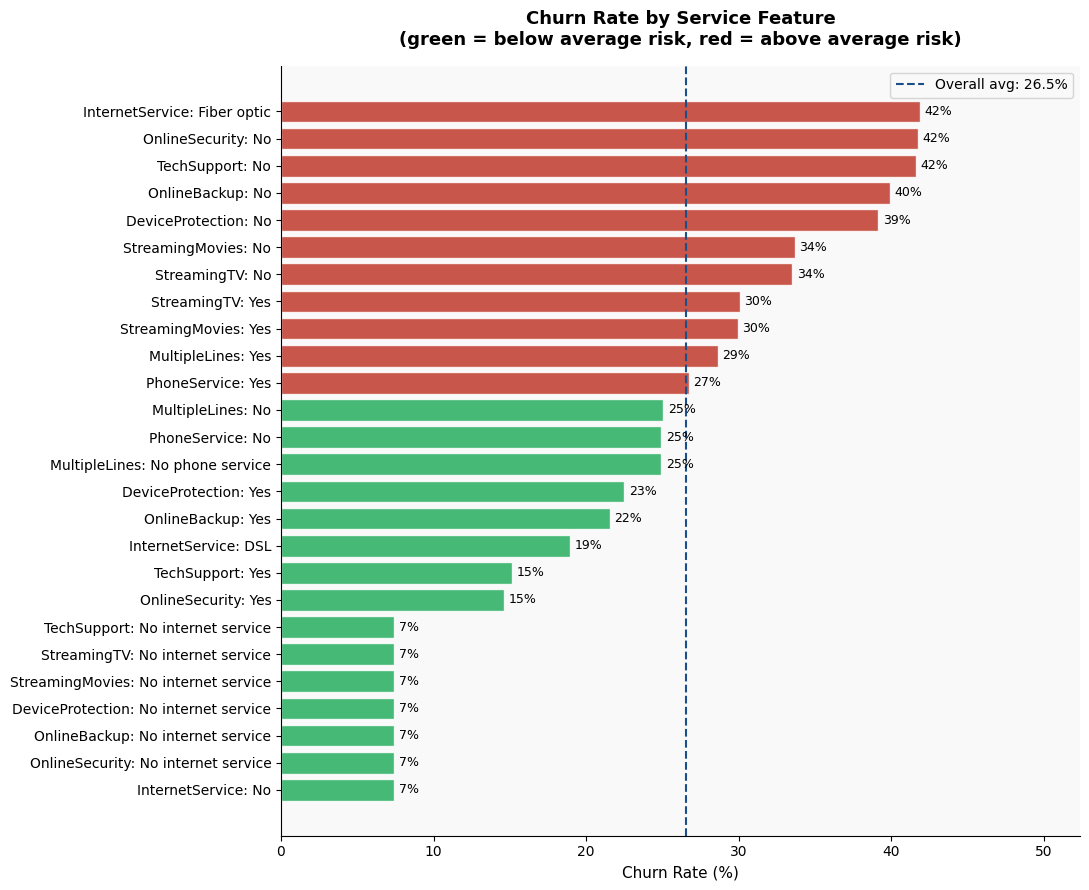


Business interpretation:
Lowest churn feature  : InternetService: No  (7%)
Highest churn feature : InternetService: Fiber optic (42%)

Online security and tech support are strongly associated with lower churn.
Recommendation: bundle these into standard plans or promote in early lifecycle.
Fibre optic internet subscribers churn at notably higher rates — flag for product team investigation.


In [12]:
service_features = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

rows = []
for feat in service_features:
    for val in df[feat].unique():
        subset = df[df[feat] == val]
        if len(subset) >= 50:
            rows.append({
                'Feature': f'{feat}: {val}',
                'ChurnRate': subset['Churn_Binary'].mean(),
                'Count': len(subset),
            })

feat_df = pd.DataFrame(rows).sort_values('ChurnRate', ascending=True)

fig, ax = plt.subplots(figsize=(11, 9))
colors = [GREEN if r < churn_rate else RED for r in feat_df['ChurnRate']]
ax.barh(feat_df['Feature'], feat_df['ChurnRate'] * 100, color=colors, alpha=0.85, edgecolor='white')
ax.axvline(churn_rate * 100, color=BLUE, linestyle='--', lw=1.5,
           label=f'Overall avg: {churn_rate*100:.1f}%')
ax.set_title('Churn Rate by Service Feature\n(green = below average risk, red = above average risk)',
             fontweight='bold', pad=15)
ax.set_xlabel('Churn Rate (%)')
for i, (_, row) in enumerate(feat_df.iterrows()):
    ax.text(row['ChurnRate'] * 100 + 0.3, i,
            f"{row['ChurnRate']*100:.0f}%", va='center', fontsize=9)
ax.legend()
ax.set_xlim(0, feat_df['ChurnRate'].max() * 100 * 1.25)

plt.tight_layout()
plt.savefig(FIGURES / '04_feature_churn_rates.png', dpi=150, bbox_inches='tight')
plt.show()

best  = feat_df.iloc[0]
worst = feat_df.iloc[-1]
print(f"\nBusiness interpretation:")
print(f"Lowest churn feature  : {best['Feature']}  ({best['ChurnRate']*100:.0f}%)")
print(f"Highest churn feature : {worst['Feature']} ({worst['ChurnRate']*100:.0f}%)")
print("\nOnline security and tech support are strongly associated with lower churn.")
print("Recommendation: bundle these into standard plans or promote in early lifecycle.")
print("Fibre optic internet subscribers churn at notably higher rates — flag for product team investigation.")


In [13]:
active  = df[df['Churn_Binary'] == 0]
churned = df[df['Churn_Binary'] == 1]

total_mrr   = df['MonthlyCharges'].sum()
active_mrr  = active['MonthlyCharges'].sum()
churn_mrr   = churned['MonthlyCharges'].sum()
avg_ltv_act = active['TotalCharges'].mean()
avg_ltv_ch  = churned['TotalCharges'].mean()

print("=" * 60)
print("REVENUE IMPACT SUMMARY")
print("=" * 60)
print(f"\nTotal subscriber base          : {len(df):,}")
print(f"  Active (retained)             : {len(active):,}")
print(f"  Churned                       : {len(churned):,}")
print(f"\nTotal MRR                      : £{total_mrr:,.0f}")
print(f"  Active MRR                    : £{active_mrr:,.0f}")
print(f"  MRR lost to churn             : £{churn_mrr:,.0f}")
print(f"\nAverage LTV — active           : £{avg_ltv_act:,.0f}")
print(f"Average LTV — churned          : £{avg_ltv_ch:,.0f}")
print(f"LTV gap (left too early)       : £{avg_ltv_act - avg_ltv_ch:,.0f} per subscriber")
print(f"\nProjected ARR (if no churn)    : £{total_mrr*12:,.0f}")
print(f"Projected ARR (current rate)   : £{active_mrr*12:,.0f}")
print(f"Annual revenue gap from churn  : £{churn_mrr*12:,.0f}")
print(f"\nA 5% churn reduction saves     : £{churn_mrr * 0.05 * 12:,.0f} per year")
print(f"A 10% churn reduction saves    : £{churn_mrr * 0.10 * 12:,.0f} per year")
print("\nThis is the financial case for retention investment.")
print("Any campaign costing less than these thresholds delivers positive ROI.")


REVENUE IMPACT SUMMARY

Total subscriber base          : 7,043
  Active (retained)             : 5,174
  Churned                       : 1,869

Total MRR                      : £456,117
  Active MRR                    : £316,986
  MRR lost to churn             : £139,131

Average LTV — active           : £2,550
Average LTV — churned          : £1,532
LTV gap (left too early)       : £1,018 per subscriber

Projected ARR (if no churn)    : £5,473,399
Projected ARR (current rate)   : £3,803,829
Annual revenue gap from churn  : £1,669,570

A 5% churn reduction saves     : £83,479 per year
A 10% churn reduction saves    : £166,957 per year

This is the financial case for retention investment.
Any campaign costing less than these thresholds delivers positive ROI.


In [14]:
from google.colab import files

print("Upload: online_retail_II.xlsx")
print("Download from: https://archive.ics.uci.edu/dataset/502/online+retail+ii")
print()
print("WARNING: This file is ~45MB. The upload may take 1–2 minutes on a standard connection.")
print("After uploading, the Excel loading step below will take another 30–60 seconds.")
print()

uploaded2 = files.upload()
print("Upload complete.")


Upload: online_retail_II.xlsx
Download from: https://archive.ics.uci.edu/dataset/502/online+retail+ii

After uploading, the Excel loading step below will take another 30–60 seconds.



Saving online+retail+ii.zip to online+retail+ii.zip
Upload complete.


In [15]:
print("Loading Online Retail II — this will take 30–60 seconds...")

df_09 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2009-2010')
df_10 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')
retail = pd.concat([df_09, df_10], ignore_index=True)

print(f"Loaded. Shape: {retail.shape[0]:,} rows x {retail.shape[1]} columns")
print(f"Date range: {retail['InvoiceDate'].min()} to {retail['InvoiceDate'].max()}")
retail.head()


Loading Online Retail II — this will take 30–60 seconds...
Loaded. Shape: 1,067,371 rows x 8 columns
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [16]:
print(f"Rows before cleaning: {len(retail):,}")

# Remove guest checkouts (no CustomerID = cannot track cohorts)
retail = retail.dropna(subset=['Customer ID'])
retail['Customer ID'] = retail['Customer ID'].astype(int)
print(f"After removing null CustomerID  : {len(retail):,}")

# Remove cancellations (Invoice starts with 'C')
retail = retail[~retail['Invoice'].astype(str).str.startswith('C')]
print(f"After removing cancellations    : {len(retail):,}")

# Remove returns (negative quantity)
retail = retail[retail['Quantity'] > 0]
print(f"After removing returns          : {len(retail):,}")

# Remove zero-price items (samples, adjustments)
retail = retail[retail['Price'] > 0]
print(f"After removing zero-price items : {len(retail):,}")

# Parse date and add time columns
retail['InvoiceDate']  = pd.to_datetime(retail['InvoiceDate'])
retail['InvoiceMonth'] = retail['InvoiceDate'].dt.to_period('M')
retail['Revenue']      = retail['Quantity'] * retail['Price']

print(f"\nFinal shape           : {retail.shape}")
print(f"Unique customers      : {retail['Customer ID'].nunique():,}")
print(f"Unique invoices       : {retail['Invoice'].nunique():,}")
print(f"Total revenue in data : £{retail['Revenue'].sum():,.0f}")
print(f"Date range            : {retail['InvoiceDate'].min().date()} to {retail['InvoiceDate'].max().date()}")


Rows before cleaning: 1,067,371
After removing null CustomerID  : 824,364
After removing cancellations    : 805,620
After removing returns          : 805,620
After removing zero-price items : 805,549

Final shape           : (805549, 10)
Unique customers      : 5,878
Unique invoices       : 36,969
Total revenue in data : £17,743,429
Date range            : 2009-12-01 to 2011-12-09


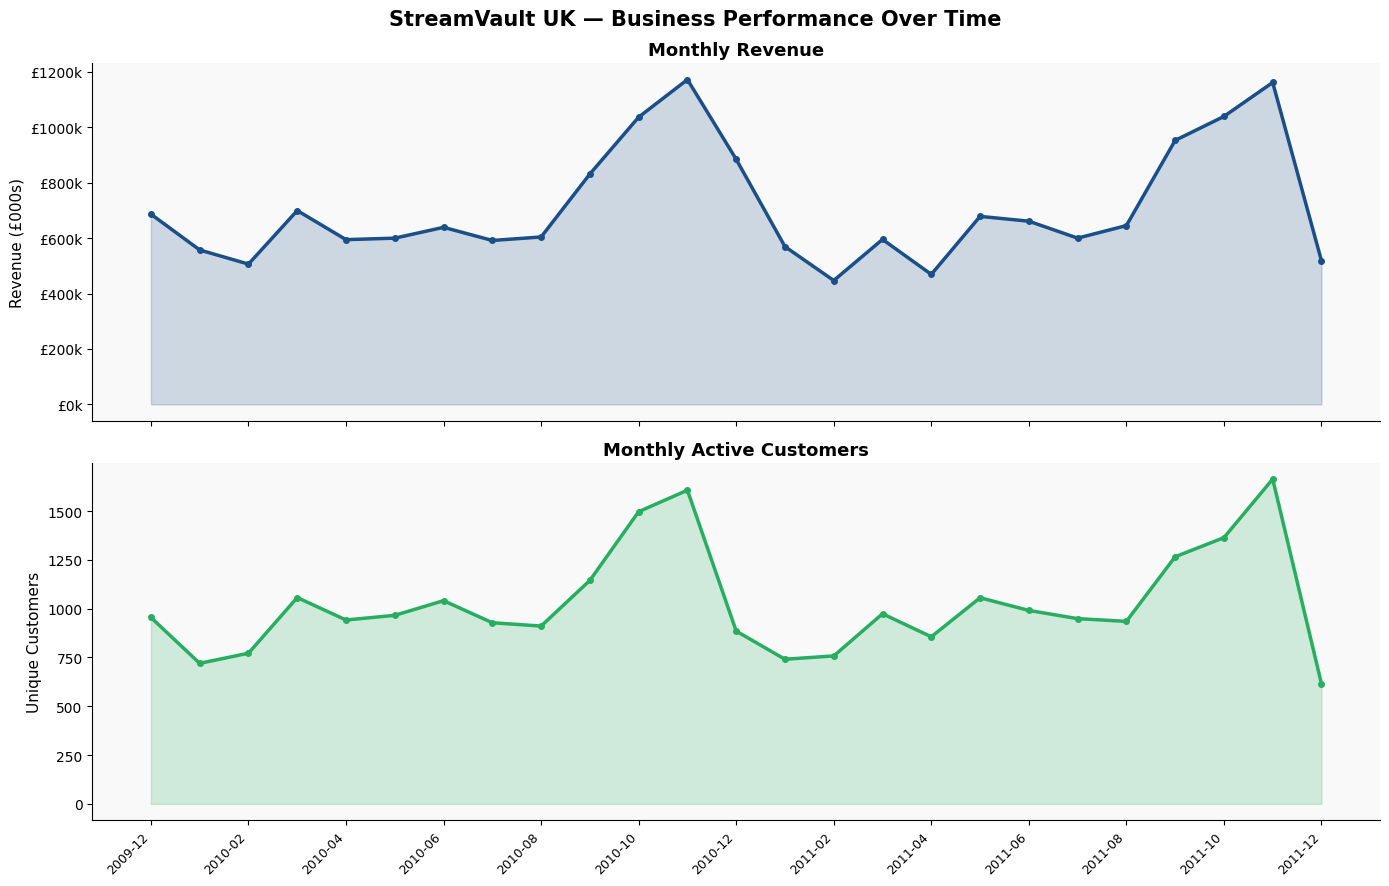

Peak revenue month: 2010-11  (£1,172,336)
Note: December 2011 is a partial month. Cohort analysis will use November 2011 as cutoff.


In [17]:
monthly_rev  = retail.groupby('InvoiceMonth')['Revenue'].sum()
monthly_cust = retail.groupby('InvoiceMonth')['Customer ID'].nunique()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
fig.suptitle('StreamVault UK — Business Performance Over Time', fontsize=15, fontweight='bold')

months_str = [str(m) for m in monthly_rev.index]
x = list(range(len(months_str)))

axes[0].fill_between(x, monthly_rev.values / 1000, alpha=0.2, color=BLUE)
axes[0].plot(x, monthly_rev.values / 1000, color=BLUE, lw=2.5, marker='o', ms=4)
axes[0].set_title('Monthly Revenue', fontweight='bold')
axes[0].set_ylabel('Revenue (£000s)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'£{v:.0f}k'))

axes[1].fill_between(x, monthly_cust.values, alpha=0.2, color=GREEN)
axes[1].plot(x, monthly_cust.values, color=GREEN, lw=2.5, marker='o', ms=4)
axes[1].set_title('Monthly Active Customers', fontweight='bold')
axes[1].set_ylabel('Unique Customers')

step = max(1, len(months_str) // 12)
axes[1].set_xticks(list(range(0, len(months_str), step)))
axes[1].set_xticklabels(months_str[::step], rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '05_revenue_trends.png', dpi=150, bbox_inches='tight')
plt.show()

peak = monthly_rev.idxmax()
print(f"Peak revenue month: {peak}  (£{monthly_rev.max():,.0f})")
print("Note: December 2011 is a partial month. Cohort analysis will use November 2011 as cutoff.")


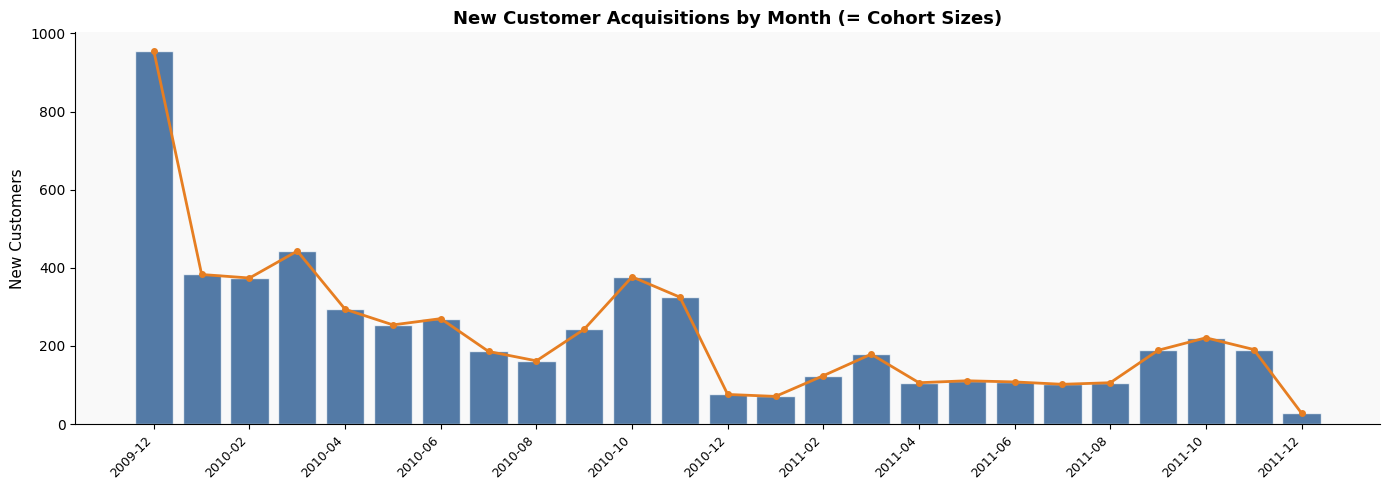

Total unique customers    : 5,878
Available for cohort work : 5,878
Cohort date range         : 2009-12 to 2011-12

This cohort map is used directly by Notebook 02.


In [18]:
# Each customer's first purchase month = their acquisition cohort
customer_first = (
    retail.groupby('Customer ID')['InvoiceMonth']
    .min()
    .reset_index()
    .rename(columns={'InvoiceMonth': 'CohortMonth'})
)

new_per_month = customer_first.groupby('CohortMonth').size()
months_str2   = [str(m) for m in new_per_month.index]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(len(months_str2)), new_per_month.values, color=BLUE, alpha=0.75, edgecolor='white')
ax.plot(range(len(months_str2)), new_per_month.values, color=ORANGE, lw=2, marker='o', ms=4)

step2 = max(1, len(months_str2) // 12)
ax.set_xticks(list(range(0, len(months_str2), step2)))
ax.set_xticklabels(months_str2[::step2], rotation=45, ha='right', fontsize=9)
ax.set_title('New Customer Acquisitions by Month (= Cohort Sizes)', fontweight='bold')
ax.set_ylabel('New Customers')

plt.tight_layout()
plt.savefig(FIGURES / '06_customer_acquisition.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total unique customers    : {retail['Customer ID'].nunique():,}")
print(f"Available for cohort work : {len(customer_first):,}")
print(f"Cohort date range         : {customer_first['CohortMonth'].min()} to {customer_first['CohortMonth'].max()}")
print("\nThis cohort map is used directly by Notebook 02.")


In [21]:
telco_out  = PROCESSED / 'telco_clean.csv'
retail_out = PROCESSED / 'online_retail_clean.parquet'
cohort_out = PROCESSED / 'customer_cohorts.csv'

df.to_csv(telco_out, index=False)
print(f"Saved: {telco_out.name}  ({len(df):,} rows)")

# Fix: cast mixed-type columns to string before writing parquet
retail['StockCode'] = retail['StockCode'].astype(str)
retail['Invoice']   = retail['Invoice'].astype(str)

retail.to_parquet(retail_out, index=False)
print(f"Saved: {retail_out.name}  ({len(retail):,} rows)")

customer_first.to_csv(cohort_out, index=False)
print(f"Saved: {cohort_out.name}  ({len(customer_first):,} rows)")

print("\nAll cleaned datasets saved to /content/processed/")
print("Proceed to Notebook 02: Cohort Retention Analysis.")


Saved: telco_clean.csv  (7,043 rows)
Saved: online_retail_clean.parquet  (805,549 rows)
Saved: customer_cohorts.csv  (5,878 rows)

All cleaned datasets saved to /content/processed/
Proceed to Notebook 02: Cohort Retention Analysis.


In [22]:
print("=" * 60)
print("NOTEBOOK 01 COMPLETE — KEY FINDINGS SUMMARY")
print("=" * 60)
print()
print(f"Overall monthly churn rate   : {churn_rate*100:.1f}%  (industry benchmark: 5–8%)")
print()
print("Churn by contract type:")
for ct, val in contract_churn.items():
    print(f"  {ct:<20} : {val*100:.1f}%")
print()
print("Churn by tenure band:")
tb_final = df.groupby('TenureBand', observed=True)['Churn_Binary'].mean()
for band, val in tb_final.items():
    print(f"  {str(band):<12} : {val*100:.0f}%")
print()
print(f"MRR at risk from churn       : £{churn_mrr:,.0f}/month  (£{churn_mrr*12:,.0f}/year)")
print(f"LTV gap per churned sub      : £{avg_ltv_act - avg_ltv_ch:,.0f}")
print()
print("Top retention levers:")
print("  1. Convert month-to-month subscribers to annual in months 1–3")
print("  2. Improve onboarding quality — 0–3 month churn is the biggest single loss")
print("  3. Bundle online security and tech support features")
print("  4. Value reinforcement campaign for £70+ subscribers")


NOTEBOOK 01 COMPLETE — KEY FINDINGS SUMMARY

Overall monthly churn rate   : 26.5%  (industry benchmark: 5–8%)

Churn by contract type:
  Month-to-month       : 42.7%
  One year             : 11.3%
  Two year             : 2.8%

Churn by tenure band:
  0–3 mo       : 56%
  4–6 mo       : 45%
  7–12 mo      : 36%
  13–24 mo     : 29%
  25–48 mo     : 20%
  49–72 mo     : 10%

MRR at risk from churn       : £139,131/month  (£1,669,570/year)
LTV gap per churned sub      : £1,018

Top retention levers:
  1. Convert month-to-month subscribers to annual in months 1–3
  2. Improve onboarding quality — 0–3 month churn is the biggest single loss
  3. Bundle online security and tech support features
  4. Value reinforcement campaign for £70+ subscribers
